# CS 521 HW4, Problem 3: PPO on CartPole

Open this notebook in Google Colab. The CPU runtime is sufficient: a GPU does not make this notebook faster.

The notebook has a complete implementation of PPO for the CartPole-v1 environment.
In part (a) of Problem 3, you run it and examine two of its parts.
In Bonus Research Question 2, you change the algorithm to improve learning.
Do not change the environment, the training budget (`total_steps`) or the evaluation.

**Environment.** CartPole-v1 gives a reward of +1 for each step. An episode ends when the pole falls
(*termination*) or after 500 steps (*truncation*, a time limit). Thus the maximum return is 500.

In [1]:
# !pip install gymnasium   # Colab has gymnasium. Remove the comment if the import fails.
import copy
import time

import gymnasium as gym
import numpy as np
import torch
import torch.nn as nn
from torch.distributions import Categorical

torch.set_num_threads(1)

CONFIG = dict(
    total_steps=200_000,   # training budget (environment steps). Do not change.
    num_envs=4,            # parallel environments
    num_steps=128,         # steps per environment for each rollout
    lr=2.5e-4,
    anneal_lr=True,        # decrease the learning rate linearly to 0
    gamma=0.99,
    gae_lambda=0.95,
    num_minibatches=4,
    update_epochs=4,
    clip_coef=0.2,
    ent_coef=0.01,
    vf_coef=0.5,
    max_grad_norm=0.5,
    norm_adv=True,         # normalize the advantages in each minibatch
)
SEEDS = [0, 1, 2, 3, 4]

# Environments

`Envs` runs `num_envs` copies of CartPole. When an episode ends, `step` resets that copy automatically.
For each copy, `step` returns:

* `obs`: the next observation. If the episode ended, this is the first observation of the new episode.
* `reward`, `terminated`, `truncated`.
* `final_obs`: the last observation of the episode that ended (`None` if the episode did not end).

`step` also records the return of each finished episode in `self.episodes` as `(global_step, return)`.

In [2]:
class Envs:
    def __init__(self, n, seed):
        self.envs = [gym.make("CartPole-v1") for _ in range(n)]
        self.obs = np.stack([e.reset(seed=seed + i)[0] for i, e in enumerate(self.envs)])
        for i, e in enumerate(self.envs):
            e.action_space.seed(seed + i)
        self.ep_return = np.zeros(n)
        self.global_step = 0
        self.episodes = []

    def step(self, actions):
        rewards, terms, truncs, final_obs = [], [], [], []
        for i, (e, a) in enumerate(zip(self.envs, actions)):
            o, r, term, trunc, _ = e.step(int(a))
            self.ep_return[i] += r
            fo = None
            if term or trunc:
                fo = o
                self.episodes.append((self.global_step + i + 1, self.ep_return[i]))
                self.ep_return[i] = 0
                o, _ = e.reset()
            self.obs[i] = o
            rewards.append(r); terms.append(term); truncs.append(trunc); final_obs.append(fo)
        self.global_step += len(self.envs)
        return self.obs.copy(), np.array(rewards), np.array(terms), np.array(truncs), final_obs

# Agent

The agent has two separate networks with 2 hidden layers of 64 neurons: the actor (policy) and the critic (value).

In [3]:
def layer_init(layer, std=np.sqrt(2), bias=0.0):
    nn.init.orthogonal_(layer.weight, std)
    nn.init.constant_(layer.bias, bias)
    return layer


class Agent(nn.Module):
    def __init__(self, obs_dim=4, n_actions=2):
        super().__init__()
        self.critic = nn.Sequential(
            layer_init(nn.Linear(obs_dim, 64)), nn.Tanh(),
            layer_init(nn.Linear(64, 64)), nn.Tanh(),
            layer_init(nn.Linear(64, 1), std=1.0))
        self.actor = nn.Sequential(
            layer_init(nn.Linear(obs_dim, 64)), nn.Tanh(),
            layer_init(nn.Linear(64, 64)), nn.Tanh(),
            layer_init(nn.Linear(64, n_actions), std=0.01))

    def get_value(self, x):
        return self.critic(x).squeeze(-1)

    def get_action_and_value(self, x, action=None):
        dist = Categorical(logits=self.actor(x))
        if action is None:
            action = dist.sample()
        return action, dist.log_prob(action), dist.entropy(), self.get_value(x)

# PPO

`compute_gae` calculates the advantages with generalized advantage estimation (GAE).
`ppo_update` does `update_epochs` passes over the rollout with the clipped surrogate objective.
`train_ppo(seed, cfg)` trains one agent and returns the agent and the list of `(global_step, return)` of the
training episodes.

In [4]:
def compute_gae(rewards, values, dones, next_value, next_done, gamma, lam):
    # rewards, values, dones: (num_steps, num_envs). dones[t] = 1 if the episode ended at step t - 1,
    # thus obs[t] is the first observation of a new episode.
    T = len(rewards)
    adv = torch.zeros_like(rewards)
    last = 0
    for t in reversed(range(T)):
        not_done = 1.0 - (next_done if t == T - 1 else dones[t + 1])
        nv = next_value if t == T - 1 else values[t + 1]
        delta = rewards[t] + gamma * nv * not_done - values[t]
        last = delta + gamma * lam * not_done * last
        adv[t] = last
    return adv, adv + values


def ppo_update(agent, opt, b, cfg):
    n = len(b["obs"])
    mb_size = n // cfg["num_minibatches"]
    stats = []
    for _ in range(cfg["update_epochs"]):
        idx = torch.randperm(n)
        for start in range(0, n, mb_size):
            mb = idx[start:start + mb_size]
            _, logp, ent, v = agent.get_action_and_value(b["obs"][mb], b["actions"][mb])
            ratio = (logp - b["logp"][mb]).exp()
            adv = b["adv"][mb]
            if cfg["norm_adv"]:
                adv = (adv - adv.mean()) / (adv.std() + 1e-8)
            pg_loss = torch.max(-adv * ratio,
                                -adv * ratio.clamp(1 - cfg["clip_coef"], 1 + cfg["clip_coef"])).mean()
            v_loss = 0.5 * ((v - b["returns"][mb]) ** 2).mean()
            loss = pg_loss - cfg["ent_coef"] * ent.mean() + cfg["vf_coef"] * v_loss
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(agent.parameters(), cfg["max_grad_norm"])
            opt.step()
            stats.append(((ratio - 1).abs() > cfg["clip_coef"]).float().mean().item())
    return {"clip_frac": float(np.mean(stats))}


def train_ppo(seed, cfg=None, verbose=False):
    cfg = {**CONFIG, **(cfg or {})}
    torch.manual_seed(seed)
    np.random.seed(seed)
    envs = Envs(cfg["num_envs"], seed)
    agent = Agent()
    opt = torch.optim.Adam(agent.parameters(), lr=cfg["lr"], eps=1e-5)
    N, T = cfg["num_envs"], cfg["num_steps"]
    n_updates = cfg["total_steps"] // (N * T)
    obs = torch.zeros(T, N, 4); actions = torch.zeros(T, N, dtype=torch.long)
    logps = torch.zeros(T, N); rewards = torch.zeros(T, N); dones = torch.zeros(T, N); values = torch.zeros(T, N)
    next_obs = torch.tensor(envs.obs, dtype=torch.float32)
    next_done = torch.zeros(N)
    start = time.time()
    for update in range(n_updates):
        if cfg["anneal_lr"]:
            opt.param_groups[0]["lr"] = cfg["lr"] * (1 - update / n_updates)
        for t in range(T):
            obs[t], dones[t] = next_obs, next_done
            with torch.no_grad():
                a, logp, _, v = agent.get_action_and_value(next_obs)
            actions[t], logps[t], values[t] = a, logp, v
            o, r, term, trunc, _ = envs.step(a.numpy())
            rewards[t] = torch.tensor(r, dtype=torch.float32)
            next_obs = torch.tensor(o, dtype=torch.float32)
            next_done = torch.tensor(term | trunc, dtype=torch.float32)
        with torch.no_grad():
            adv, returns = compute_gae(rewards, values, dones, agent.get_value(next_obs), next_done,
                                       cfg["gamma"], cfg["gae_lambda"])
        b = {"obs": obs.reshape(-1, 4), "actions": actions.reshape(-1), "logp": logps.reshape(-1),
             "adv": adv.reshape(-1), "returns": returns.reshape(-1)}
        stats = ppo_update(agent, opt, b, cfg)
        if verbose and (update + 1) % 20 == 0:
            recent = [r for _, r in envs.episodes[-10:]]
            print(f"step {envs.global_step:6d}  mean return (last 10) {np.mean(recent):6.1f}  "
                  f"clip frac {stats['clip_frac']:.3f}")
    return agent, envs.episodes, time.time() - start

# Evaluation

`evaluate_policy` runs the greedy policy (the action with the highest probability) for 20 episodes with fixed seeds.
`summarize(runs)` gives these metrics for a list of runs (one run for each seed):

* `auc`: the mean of the learning curve over the training budget. The learning curve is the mean return of the last
  10 training episodes, at 100 equally spaced steps. A higher value means faster learning.
* `steps_to_475`: the first step where the mean return of the last 10 training episodes is at least 475.
  If a run does not get there, we use `total_steps`.
* `final`: the return of the greedy policy at the end of training.

`plot_curves` plots the mean learning curve over the seeds. Use these functions for all the numbers in your report.

In [5]:
@torch.no_grad()
def evaluate_policy(agent, episodes=20, seed=10_000):
    env = gym.make("CartPole-v1")
    total = 0.0
    for k in range(episodes):
        o, _ = env.reset(seed=seed + k)
        done = False
        while not done:
            a = agent.actor(torch.tensor(o, dtype=torch.float32)).argmax().item()
            o, r, term, trunc, _ = env.step(a)
            total += r
            done = term or trunc
    return total / episodes


def learning_curve(episodes, total_steps=CONFIG["total_steps"], points=100, window=10):
    steps = np.array([s for s, _ in episodes])
    rets = np.array([r for _, r in episodes])
    grid = np.linspace(total_steps / points, total_steps, points)
    curve = []
    for g in grid:
        r = rets[steps <= g][-window:]
        curve.append(r.mean() if len(r) else 0.0)
    return grid, np.array(curve)


def steps_to(episodes, target=475, window=10, total_steps=CONFIG["total_steps"]):
    rets = [r for _, r in episodes]
    for k in range(window, len(episodes) + 1):
        if np.mean(rets[k - window:k]) >= target:
            return episodes[k - 1][0]
    return total_steps


def run_seeds(cfg=None, seeds=SEEDS, train_fn=None, verbose=True):
    train_fn = train_fn or train_ppo
    runs = []
    for s in seeds:
        agent, episodes, sec = train_fn(s, cfg)
        runs.append({"seed": s, "episodes": episodes, "time": sec, "final": evaluate_policy(agent)})
        if verbose:
            print(f"seed {s}: auc {learning_curve(episodes)[1].mean():6.1f}  steps_to_475 {steps_to(episodes):6d}  "
                  f"final {runs[-1]['final']:6.1f}  time {sec:5.1f} s")
    return runs


def summarize(runs, name=""):
    auc = [learning_curve(r["episodes"])[1].mean() for r in runs]
    st = [steps_to(r["episodes"]) for r in runs]
    fin = [r["final"] for r in runs]
    res = {"name": name, "auc": np.mean(auc), "auc_std": np.std(auc), "steps_to_475": np.mean(st),
           "solved": sum(s < CONFIG["total_steps"] for s in st), "final": np.mean(fin),
           "final_std": np.std(fin), "time": np.mean([r["time"] for r in runs])}
    print(f"{name:<24} auc {res['auc']:6.1f} +- {res['auc_std']:5.1f}  steps_to_475 {res['steps_to_475']:8.0f} "
          f"({res['solved']}/{len(runs)} runs)  final {res['final']:6.1f} +- {res['final_std']:5.1f}  "
          f"time {res['time']:5.1f} s")
    return res


def plot_curves(named_runs):
    import matplotlib.pyplot as plt
    for name, runs in named_runs.items():
        curves = np.stack([learning_curve(r["episodes"])[1] for r in runs])
        grid = learning_curve(runs[0]["episodes"])[0]
        m, s = curves.mean(0), curves.std(0)
        plt.plot(grid, m, label=name)
        plt.fill_between(grid, m - s, m + s, alpha=0.2)
    plt.xlabel("environment steps"); plt.ylabel("mean return (last 10 episodes)"); plt.legend(); plt.show()

# (a) Run PPO

Train PPO with the default configuration for the 5 seeds. Then train two changed versions:

* Without clipping: `{"clip_coef": 1e9}`.
* Without GAE (Monte Carlo advantages): `{"gae_lambda": 1.0}`.

seed 0: auc  303.8  steps_to_475 200000  final  478.4  time  71.2 s
seed 1: auc  252.2  steps_to_475  78448  final  309.9  time  69.7 s
seed 2: auc  299.4  steps_to_475  66675  final  450.3  time  69.1 s
seed 3: auc  303.5  steps_to_475  95457  final  399.6  time  68.5 s
seed 4: auc  268.2  steps_to_475  69735  final  471.2  time  69.2 s
seed 0: auc  368.3  steps_to_475  67872  final  500.0  time  68.3 s
seed 1: auc  360.5  steps_to_475  97746  final  500.0  time  68.0 s
seed 2: auc  382.3  steps_to_475  66643  final  497.6  time  68.0 s
seed 3: auc  320.2  steps_to_475  74677  final  500.0  time  68.1 s
seed 4: auc  313.5  steps_to_475  84618  final  414.2  time  68.1 s
seed 0: auc  340.7  steps_to_475 141178  final  500.0  time  68.1 s
seed 1: auc  332.1  steps_to_475 146040  final  500.0  time  67.6 s
seed 2: auc  247.8  steps_to_475  76393  final  471.9  time  69.9 s
seed 3: auc  268.0  steps_to_475 200000  final  500.0  time  67.9 s
seed 4: auc  349.1  steps_to_475 106907  final  

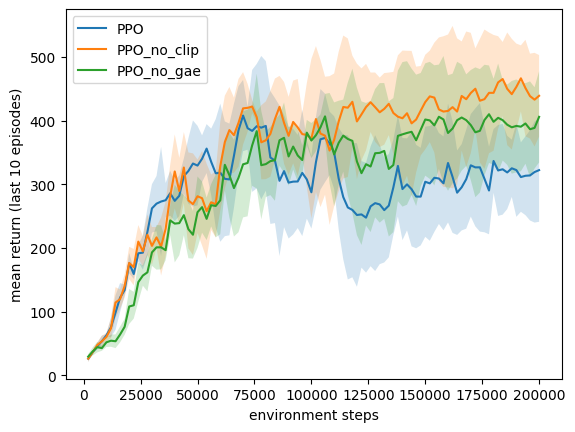

In [6]:
all_runs = {"PPO": run_seeds()}
all_runs["PPO_no_clip"] = run_seeds(cfg={"clip_coef": 1e9})
all_runs["PPO_no_gae"] = run_seeds(cfg={"gae_lambda": 1.0})
# TODO: train the two changed versions
# raise NotImplementedError
results = {name: summarize(runs, name) for name, runs in all_runs.items()}
plot_curves(all_runs)

## Part (b)

In [7]:
%pip -q install "lm_eval==0.4.9" "transformers==4.52.4" "datasets==3.6.0" "accelerate==1.7.0" "peft==0.15.2" pandas

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2025.3.0 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 wh

In [8]:
MODELS = {
    "Base": "allenai/OLMo-2-0425-1B",
    "SFT": "allenai/OLMo-2-0425-1B-SFT",
    "DPO": "allenai/OLMo-2-0425-1B-DPO",
    "RLVR": "allenai/OLMo-2-0425-1B-Instruct",
}

In [9]:
import copy
import gc
import hashlib
import importlib.metadata
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from IPython.display import display
from huggingface_hub import model_info
from lm_eval import evaluator
from lm_eval.models.huggingface import HFLM
from lm_eval.tasks import TaskManager, get_task_dict
from lm_eval.utils import handle_non_serializable

MODELS = {
    "Base": "allenai/OLMo-2-0425-1B",
    "SFT": "allenai/OLMo-2-0425-1B-SFT",
    "DPO": "allenai/OLMo-2-0425-1B-DPO",
    "RLVR (Instruct)": "allenai/OLMo-2-0425-1B-Instruct",
}
TASK_NAMES = ["gsm8k", "truthfulqa_mc1"]
N_EXAMPLES = 200
SEED = 521
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = "float16" if DEVICE == "cuda" else "float32"
OUT = Path("p3b_results")
OUT.mkdir(exist_ok=True)
GENERATION = {"do_sample": False, "temperature": 0.0, "max_gen_toks": 512,
              "until": ["Question:", "</s>", "<|im_end|>", "<|endoftext|>"]}
GSM_PROMPT = (
    "Solve the following math problem. Explain your reasoning and end with "
    "'#### <number>'.\n\nQuestion: {{question}}\nAnswer:"
)

def save_json(path, data):
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(data, indent=2, ensure_ascii=False,
                                    default=handle_non_serializable))
    temporary.replace(path)

def make_tasks():
    tasks = get_task_dict(TASK_NAMES, task_manager=TaskManager())
    tasks["gsm8k"].set_config("num_fewshot", 0)
    tasks["gsm8k"].set_config("doc_to_text", GSM_PROMPT)
    tasks["gsm8k"].set_config("generation_kwargs", copy.deepcopy(GENERATION))
    return tasks

print("Device:", DEVICE)
if DEVICE == "cpu":
    print("For the full four-model evaluation, select a Colab GPU runtime; CPU generation is slow.")
print("Results folder:", OUT.resolve())

Device: cuda
Results folder: /content/p3b_results


In [10]:
manifest_path = OUT / "manifest.json"
tasks = make_tasks()
selection = {}
for name, task in tasks.items():
    docs = task.eval_docs
    indices = sorted(random.Random(SEED).sample(range(len(docs)), N_EXAMPLES))
    selection[name] = {
        "indices": indices,
        "dataset_fingerprint": getattr(docs, "_fingerprint", None),
        "documents": [docs[i] for i in indices],
    }
settings = {
    "models": MODELS, "seed": SEED, "n_examples": N_EXAMPLES,
    "gsm_prompt": GSM_PROMPT, "generation": GENERATION,
    "device": DEVICE, "dtype": DTYPE, "selection": selection,
    "packages": {name: importlib.metadata.version(name) for name in
                 ["lm_eval", "transformers", "datasets", "accelerate", "peft", "torch"]},
}
if manifest_path.exists():
    manifest = json.loads(manifest_path.read_text())
    if manifest["settings"] != settings:
        raise ValueError("Settings or datasets changed. Use a new OUT folder for a new experiment.")
else:
    manifest = {"settings": settings,
                "revisions": {stage: model_info(repo).sha for stage, repo in MODELS.items()}}
    save_json(manifest_path, manifest)
manifest_hash = hashlib.sha256(json.dumps(manifest, sort_keys=True).encode()).hexdigest()
sample_indices = {name: item["indices"] for name, item in selection.items()}
print("Manifest:", manifest_hash)
print({name: len(indices) for name, indices in sample_indices.items()})
del tasks

README.md: 0.00B [00:00, ?B/s]

main/train-00000-of-00001.parquet:   0%|          | 0.00/2.31M [00:00<?, ?B/s]

main/test-00000-of-00001.parquet:   0%|          | 0.00/419k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/7473 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1319 [00:00<?, ? examples/s]

README.md: 0.00B [00:00, ?B/s]

multiple_choice/validation-00000-of-0000(…):   0%|          | 0.00/271k [00:00<?, ?B/s]

Generating validation split:   0%|          | 0/817 [00:00<?, ? examples/s]

Manifest: 68d4233fdeb5a8b792fa1e73789e3b79572c65d5b4d7fadc6b48babf130575ec
{'truthfulqa_mc1': 200, 'gsm8k': 200}


In [11]:
all_results = {}
for stage, repo in MODELS.items():
    result_path = OUT / f"{stage.split()[0].lower()}_results.json"
    if result_path.exists():
        payload = json.loads(result_path.read_text())
        if payload.get("manifest_hash") != manifest_hash:
            raise ValueError(f"{result_path} belongs to a different experiment.")
        all_results[stage] = payload["evaluation"]
        print("Reused:", stage)
        continue

    print("Evaluating:", stage, repo, flush=True)
    lm = HFLM(pretrained=repo, revision=manifest["revisions"][stage],
              device=DEVICE, dtype=DTYPE, batch_size=1,
              max_length=2048, trust_remote_code=False)
    if stage != "Base" and not lm.tokenizer.chat_template:
        raise ValueError(f"Native chat template missing for {repo}.")
    try:
        fresh_tasks = make_tasks()
        result = evaluator.simple_evaluate(
            model=lm, tasks=list(fresh_tasks.values()),
            samples=sample_indices, num_fewshot=0,
            apply_chat_template=(stage != "Base"), fewshot_as_multiturn=False,
            log_samples=True, cache_requests=False, bootstrap_iters=1000,
            random_seed=SEED, numpy_random_seed=SEED,
            torch_random_seed=SEED, fewshot_random_seed=SEED,
        )
        # Verify identical documents, not just an identical number of examples.
        for name in TASK_NAMES:
            expected = {json.dumps(doc, sort_keys=True) for doc in selection[name]["documents"]}
            observed = {json.dumps(row["doc"], sort_keys=True) for row in result["samples"][name]}
            if observed != expected:
                raise ValueError(f"Evaluated documents do not match the manifest: {name}")
        payload = {"stage": stage, "repository": repo, "manifest_hash": manifest_hash,
                   "native_chat_template": lm.tokenizer.chat_template if stage != "Base" else None,
                   "evaluation": result}
        save_json(result_path, payload)
        all_results[stage] = result
    finally:
        del lm
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

Evaluating: Base allenai/OLMo-2-0425-1B


config.json:   0%|          | 0.00/623 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

... (36 outputs left out)

special_tokens_map.json:   0%|          | 0.00/581 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/2.97G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/121 [00:00<?, ?B/s]

Running generate_until requests: 100%|██████████| 200/200 [13:54<00:00,  4.17s/it]


In [12]:
rows = []
for stage, result in all_results.items():
    gsm = result["results"]["gsm8k"]
    truth = result["results"]["truthfulqa_mc1"]
    rows.append({
        "Checkpoint": stage,
        "GSM8K strict (%)": 100 * gsm["exact_match,strict-match"],
        "GSM8K flexible (%)": 100 * gsm["exact_match,flexible-extract"],
        "TruthfulQA MC1 (%)": 100 * truth["acc,none"],
    })
table = pd.DataFrame(rows).set_index("Checkpoint").reindex(MODELS)
display(table.round(2))
table.to_csv(OUT / "scores.csv")
deltas = table.diff().iloc[1:]
deltas.index = ["Base → SFT", "SFT → DPO", "DPO → RLVR"]
print("Changes in percentage points:")
display(deltas.round(2))
deltas.to_csv(OUT / "stage_changes.csv")

,GSM8K strict (%),GSM8K flexible (%),TruthfulQA MC1 (%)
Checkpoint,,,
Base,9.0,25.5,22.0
SFT,32.5,52.5,24.5
DPO,44.0,59.5,27.0
RLVR (Instruct),27.5,71.0,29.5


Changes in percentage points:


,GSM8K strict (%),GSM8K flexible (%),TruthfulQA MC1 (%)
Base → SFT,23.5,27.0,2.5
SFT → DPO,11.5,7.0,2.5
DPO → RLVR,-16.5,11.5,2.5


In [13]:
# Actual model outputs, selected by the same document IDs for all checkpoints.
example_rows = []
for task_name in TASK_NAMES:
    chosen_ids = sample_indices[task_name][:3]
    for doc_id in chosen_ids:
        for stage, result in all_results.items():
            candidates = [row for row in result["samples"][task_name] if row["doc_id"] == doc_id]
            sample = next((row for row in candidates if row["filter"] == "strict-match"), candidates[0])
            doc = sample["doc"]
            if task_name == "gsm8k":
                output = sample["resps"][0][0]
                reference = doc["answer"]
            else:
                # Each continuation is scored by its summed log-likelihood.
                scores = [float(response[0][0]) for response in sample["resps"]]
                predicted = int(np.argmax(scores))
                output = doc["mc1_targets"]["choices"][predicted]
                reference = doc["mc1_targets"]["choices"][doc["mc1_targets"]["labels"].index(1)]
            example_rows.append({"Benchmark": task_name, "Document ID": doc_id,
                                 "Checkpoint": stage, "Question": doc["question"],
                                 "Output": output, "Reference": reference})
            print(f"\n{task_name} | example {doc_id} | {stage}")
            print("QUESTION:", doc["question"])
            print("OUTPUT:", output)
            print("REFERENCE:", reference)
examples = pd.DataFrame(example_rows)
examples.to_csv(OUT / "example_outputs.csv", index=False)
save_json(OUT / "example_outputs.json", example_rows)


gsm8k | example 0 | Base
QUESTION: Janet’s ducks lay 16 eggs per day. She eats three for breakfast every morning and bakes muffins for her friends every day with four. She sells the remainder at the farmers' market daily for $2 per fresh duck egg. How much in dollars does she make every day at the farmers' market?
OUTPUT:  16 eggs x $2 = $32
3 eggs x $2 = $6
4 eggs x $2 = $8
$32 + $6 + $8 = $46
#### 46
The answer is: 46
REFERENCE: Janet sells 16 - 3 - 4 = <<16-3-4=9>>9 duck eggs a day.
She makes 9 * 2 = $<<9*2=18>>18 every day at the farmer’s market.
#### 18

gsm8k | example 0 | SFT
QUESTION: Janet’s ducks lay 16 eggs per day. She eats three for breakfast every morning and bakes muffins for her friends every day with four. She sells the remainder at the farmers' market daily for $2 per fresh duck egg. How much in dollars does she make every day at the farmers' market?
OUTPUT: First find how many eggs Janet eats for breakfast: 3 eggs * 1 day = 3 eggs. Then subtract that number from the

# Bonus Research Question 2: your method

Write your method as a copy of `train_ppo` (and of the other functions that you change).
Use `run_seeds(train_fn=my_train_ppo)` and `summarize` for the results.

In [14]:
def my_train_ppo(seed, cfg=None, verbose=False, options=None):
    """PPO with time-limit bootstrapping and separate gradient clipping."""
    options = options or {}
    bootstrap_timeouts = options.get("bootstrap_timeouts", True)
    split_grad_clip = options.get("split_grad_clip", True)
    diagnostics = options.get("diagnostics")
    timeout_count = 0
    timeout_bonus_sum = 0.0
    actor_freed_count = 0
    minibatch_count = 0

    cfg = {**CONFIG, **(cfg or {})}
    torch.manual_seed(seed)
    np.random.seed(seed)
    envs = Envs(cfg["num_envs"], seed)
    agent = Agent()
    opt = torch.optim.Adam(agent.parameters(), lr=cfg["lr"], eps=1e-5)
    N, T = cfg["num_envs"], cfg["num_steps"]
    n_updates = cfg["total_steps"] // (N * T)
    obs = torch.zeros(T, N, 4); actions = torch.zeros(T, N, dtype=torch.long)
    logps = torch.zeros(T, N); rewards = torch.zeros(T, N); dones = torch.zeros(T, N); values = torch.zeros(T, N)
    next_obs = torch.tensor(envs.obs, dtype=torch.float32)
    next_done = torch.zeros(N)
    start = time.time()
    for update in range(n_updates):
        if cfg["anneal_lr"]:
            opt.param_groups[0]["lr"] = cfg["lr"] * (1 - update / n_updates)
        for t in range(T):
            obs[t], dones[t] = next_obs, next_done
            with torch.no_grad():
                a, logp, _, v = agent.get_action_and_value(next_obs)
            actions[t], logps[t], values[t] = a, logp, v
            o, r, term, trunc, final_obs = envs.step(a.numpy())
            rewards[t] = torch.tensor(r, dtype=torch.float32)
            timeouts = np.flatnonzero(trunc & ~term)
            timeout_count += len(timeouts)
            if bootstrap_timeouts and len(timeouts):
                # o contains the next episode's initial state at a timeout.
                # The TD target uses the final state of the episode that ended.
                final_states = torch.as_tensor(np.stack([final_obs[i] for i in timeouts]),
                                               dtype=torch.float32)
                with torch.no_grad():
                    timeout_bonus = cfg["gamma"] * agent.get_value(final_states)
                rewards[t, timeouts] += timeout_bonus
                timeout_bonus_sum += timeout_bonus.sum().item()
            # The original done mask still stops GAE at every episode boundary.
            next_obs = torch.tensor(o, dtype=torch.float32)
            next_done = torch.tensor(term | trunc, dtype=torch.float32)
        with torch.no_grad():
            adv, returns = compute_gae(rewards, values, dones, agent.get_value(next_obs), next_done,
                                       cfg["gamma"], cfg["gae_lambda"])
        b = {"obs": obs.reshape(-1, 4), "actions": actions.reshape(-1), "logp": logps.reshape(-1),
             "adv": adv.reshape(-1), "returns": returns.reshape(-1)}
        if split_grad_clip:
            stats = ppo_update_split_clip(agent, opt, b, cfg)
            actor_freed_count += stats["actor_freed_count"]
            minibatch_count += stats["minibatch_count"]
        else:
            stats = ppo_update(agent, opt, b, cfg)
        if verbose and (update + 1) % 20 == 0:
            recent = [r for _, r in envs.episodes[-10:]]
            print(f"step {envs.global_step:6d}  mean return (last 10) {np.mean(recent):6.1f}  "
                  f"clip frac {stats['clip_frac']:.3f}")
    if diagnostics is not None:
        diagnostics.append({
            "seed": seed,
            "steps": envs.global_step,
            "timeouts": timeout_count,
            "timeout_bonus_sum": timeout_bonus_sum,
            "actor_freed_count": actor_freed_count,
            "minibatch_count": minibatch_count,
        })
    return agent, envs.episodes, time.time() - start


def ppo_update_split_clip(agent, opt, b, cfg):
    n = len(b["obs"])
    mb_size = n // cfg["num_minibatches"]
    stats = []
    actor_freed_count = 0
    limit = cfg["max_grad_norm"]
    for _ in range(cfg["update_epochs"]):
        idx = torch.randperm(n)
        for start in range(0, n, mb_size):
            mb = idx[start:start + mb_size]
            _, logp, ent, v = agent.get_action_and_value(b["obs"][mb], b["actions"][mb])
            ratio = (logp - b["logp"][mb]).exp()
            adv = b["adv"][mb]
            if cfg["norm_adv"]:
                adv = (adv - adv.mean()) / (adv.std() + 1e-8)
            pg_loss = torch.max(-adv * ratio,
                                -adv * ratio.clamp(1 - cfg["clip_coef"], 1 + cfg["clip_coef"])).mean()
            v_loss = 0.5 * ((v - b["returns"][mb]) ** 2).mean()
            loss = pg_loss - cfg["ent_coef"] * ent.mean() + cfg["vf_coef"] * v_loss
            opt.zero_grad()
            loss.backward()
            actor_norm = nn.utils.clip_grad_norm_(agent.actor.parameters(), limit).item()
            critic_norm = nn.utils.clip_grad_norm_(agent.critic.parameters(), limit).item()
            # Compare the clipping rule on these same pre-clipping gradients.
            if actor_norm <= limit < np.hypot(actor_norm, critic_norm):
                actor_freed_count += 1
            opt.step()
            stats.append(((ratio - 1).abs() > cfg["clip_coef"]).float().mean().item())
    return {"clip_frac": float(np.mean(stats)),
            "actor_freed_count": actor_freed_count, "minibatch_count": len(stats)}


In [15]:
from functools import partial
from IPython.display import Markdown, display

bonus_diagnostics = {name: [] for name in ("Full method", "Timeout bootstrap only", "Separate clipping only")}
bonus_runs = {"PPO": all_runs["PPO"]}
bonus_runs["Full method"] = run_seeds(train_fn=partial(
    my_train_ppo, options={"diagnostics": bonus_diagnostics["Full method"]}))
bonus_runs["Timeout bootstrap only"] = run_seeds(train_fn=partial(
    my_train_ppo, options={"split_grad_clip": False, "diagnostics": bonus_diagnostics["Timeout bootstrap only"]}))
bonus_runs["Separate clipping only"] = run_seeds(train_fn=partial(
    my_train_ppo, options={"bootstrap_timeouts": False, "diagnostics": bonus_diagnostics["Separate clipping only"]}))


seed 0: auc  304.3  steps_to_475 138937  final  500.0  time 102.1 s
seed 1: auc  250.3  steps_to_475 200000  final  475.6  time  73.7 s
seed 2: auc  344.2  steps_to_475 132424  final  500.0  time  68.7 s
seed 3: auc  356.1  steps_to_475  89259  final  500.0  time  68.3 s
seed 4: auc  398.2  steps_to_475  69842  final  500.0  time  69.4 s
seed 0: auc  303.8  steps_to_475 182157  final  500.0  time  68.0 s
seed 1: auc  356.1  steps_to_475 116098  final  500.0  time  68.5 s
seed 2: auc  341.8  steps_to_475  95473  final  500.0  time  67.8 s
seed 3: auc  317.6  steps_to_475 148377  final  500.0  time  68.5 s
seed 4: auc  281.3  steps_to_475  90196  final  200.6  time  70.8 s
seed 0: auc  398.0  steps_to_475  55882  final  500.0  time  70.1 s
seed 1: auc  282.5  steps_to_475 200000  final  444.0  time  68.3 s
seed 2: auc  396.7  steps_to_475  94961  final  500.0  time  69.0 s
seed 3: auc  347.3  steps_to_475 113035  final  500.0  time  68.3 s
seed 4: auc  383.4  steps_to_475  86116  final  

PPO                      auc  285.4 +-  21.3  steps_to_475   102063 (4/5 runs)  final  421.9 +-  62.4  time  69.5 s
Full method              auc  330.6 +-  50.1  steps_to_475   126092 (4/5 runs)  final  495.1 +-   9.8  time  76.4 s
Timeout bootstrap only   auc  320.1 +-  26.6  steps_to_475   126460 (5/5 runs)  final  440.1 +- 119.8  time  68.7 s
Separate clipping only   auc  361.6 +-  43.6  steps_to_475   109999 (4/5 runs)  final  488.8 +-  22.4  time  69.0 s


| Variant | AUC (mean ± SD) | Steps to 475 | Reached 475 | Final greedy return (mean ± SD) |
|---|---:|---:|---:|---:|
| PPO | 285.41 ± 21.25 | 102,063 | 4/5 | 421.86 ± 62.42 |
| Full method | 330.62 ± 50.08 | 126,092 | 4/5 | 495.12 ± 9.76 |
| Timeout bootstrap only | 320.11 ± 26.61 | 126,460 | 5/5 | 440.12 ± 119.76 |
| Separate clipping only | 361.58 ± 43.60 | 109,999 | 4/5 | 488.80 ± 22.40 |

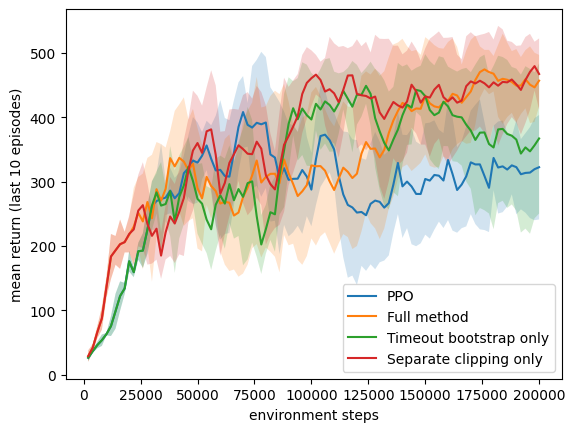

Full method: 723 pure timeouts across all five seeds
  Mean added value at a timeout: 54.98
  Actor within its own cap while joint norm exceeds cap: 90.7% of minibatches
Timeout bootstrap only: 686 pure timeouts across all five seeds
  Mean added value at a timeout: 53.02
Separate clipping only: 943 pure timeouts across all five seeds
  Actor within its own cap while joint norm exceeds cap: 92.2% of minibatches


In [16]:
bonus_results = {name: summarize(runs, name) for name, runs in bonus_runs.items()}
table = [
    "| Variant | AUC (mean ± SD) | Steps to 475 | Reached 475 | Final greedy return (mean ± SD) |",
    "|---|---:|---:|---:|---:|",
]
for name, row in bonus_results.items():
    table.append(f"| {name} | {row['auc']:.2f} ± {row['auc_std']:.2f} | "
                 f"{row['steps_to_475']:,.0f} | {row['solved']}/{len(SEEDS)} | "
                 f"{row['final']:.2f} ± {row['final_std']:.2f} |")
display(Markdown("\n".join(table)))
plot_curves(bonus_runs)

for name, rows in bonus_diagnostics.items():
    timeouts = sum(row["timeouts"] for row in rows)
    print(f"{name}: {timeouts} pure timeouts across all five seeds")
    if name != "Separate clipping only" and timeouts:
        bonus = sum(row["timeout_bonus_sum"] for row in rows) / timeouts
        print(f"  Mean added value at a timeout: {bonus:.2f}")
    updates = sum(row["minibatch_count"] for row in rows)
    if updates:
        freed = sum(row["actor_freed_count"] for row in rows)
        print(f"  Actor within its own cap while joint norm exceeds cap: {freed / updates:.1%} of minibatches")
